# CASALS -> 3DEP vertical datum alignment

Meeting-informed experiment, 2026-10-15. Both current L1B granules are reread; class-2 LAZ ground surfaces are rebuilt at the fixed historical ROI pulse locations. All output goes to a new run directory. The [preserved audit](elevation_reference_audit.ipynb) retains every original cell and executed image.

**Residual = transformed CASALS height - 3DEP reference height**, in metres. No residual clipping, fitted geoid difference, production change, or atmospheric correction enters the geodetic result.

## Physical evidence and comparison methods

Jeff Lee's [Goddard meeting statements](../../../docs/meeting/20261015_140029.txt) establish WGS84, ellipsoidal `refh`, EGM2008 tide-free geoid, and mean-tide correction fields. They do **not** establish the full `refh` processing formula, GNSS realization/epoch, correction application status, or every field's sign.

| Method | Height | Interpretation |
|---|---|---|
| Native | `refh` | Ellipsoidal baseline; intentionally unlike NAVD88 |
| EGM2008 | `refh - geoid` | Physically supported EGM2008 geoid-referenced height; not NAVD88 |
| Tide minus / plus | `refh - geoid +/- geoid_free2mean` | Sign-assumption sensitivity only; no confirmed complete height-system conversion |
| GEOID18 | Existing C7 PROJ XYZ operation | Target-compatible NAVD88/GEOID18 path, provisional input frame |

GEOID18 is retained because the audited 3DEP products use it, independent of measured RMSE. [NOAA](https://geodesy.noaa.gov/GEOID/GEOID18/geoid18_tech_details.shtml) requires NAD83(2011), epoch 2010.0 ellipsoid heights. The existing EPSG:4979 WGS84 ensemble -> EPSG:6347 + EPSG:5703 operation uses `us_noaa_g2018u0.tif`. Its WGS84/NAD83 frame component is numerically a no-op (2 m stated accuracy), not a realization/epoch solution. CASALS WGS84 realization, coordinate epoch, and the physical validity of that frame step remain unverified; the combined 2.015 m PROJ accuracy is metadata, not observed uncertainty.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
# Supports execution from the repository root or this notebook directory.
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'casals_l1b').is_dir()
sys.path.insert(0, str(ROOT))
from research.reference.vertical_alignment import run_alignment, plot_results
RUN_DIR = ROOT / 'outputs/notebooks/geolocation/vertical_datum_alignment/runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')


## Fixed populations and reference support

The primary relative comparison uses the existing, separate open-field calibration and test sites, with accepted low-slope class-2 support. Calibration uses only the historical `calibration_offset` half; the former candidate-selection half is not used to fit offsets. Geometry and pulse IDs were frozen in the prior experiment. SNR >= 5 is the high-quality headline; SNR >= 3 and all-valid strata retain every tail.

These field polygons have uncertain seasonal cover: dated NAIP is scene context, not confirmation of a ground return in November 2024. The reviewed road interiors therefore remain a separate, conditional likely-ground check. Their calibration lacks high-SNR support, so no road empirical correction is issued.

Reuse: 0.75 m grid; every 10,000th LAZ record withheld; class 2 only; >=6 neighbors within 3 m; robust plane slope <=5 degrees; plane residual NMAD <=0.20 m. This robust **reference** fit is the original interpolation algorithm; CASALS residual outliers are never removed. All methods share the same pulse IDs and finite/accepted reference mask. Current C7 XY must match the original query XY before using one reference height across methods.

All methods use the recomputed C7 local plane. The original full-grid plane differs by at most 1.51 mm / 1.21 mm; C7 local-plane heights reproduce the saved baseline exactly. This prevents reference interpolation differences from entering method comparisons.

Audited 3DEP pairs: Maryland `MD_Southeast_1_2019` / `MD_Southeast_2019_D20` and North Carolina `NC_HurricaneFlorence_9_2020` / `NC_HurricaneFlorence_2020_D20`, both interpreted as NAVD88/GEOID18 from the [source audit](../../../docs/casals_l1b_validation_report.md). The Maryland generic XML GEOID12B conflict is retained in that audit; final product evidence identifies GEOID18.

In [2]:
R = run_alignment(RUN_DIR)
METRIC_COLUMNS = ['granule_id', 'population', 'stratum', 'method', 'eligible_n', 'n', 'coverage',
                  'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(R['sites'][['granule_id', 'roi_id', 'site_id', 'split', 'pulse_count', 'calibration_test_site_spacing_m']])
display(Markdown('**Recomputed C7 parity and EGM2008 numeric audit**'))
display(R['parity'].round(12))
display(R['geoid'].round(8))
print('New output:', RUN_DIR.relative_to(ROOT))

Processing casals_l1b_20241112T165718_001_02: current H5 and class-2 LAZ


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


Processing casals_l1b_20241118T171757_001_02: current H5 and class-2 LAZ


C:\Users\zhong267\AppData\Local\miniconda3\envs\map\Lib\site-packages\pyproj\transformer.py:207: UserWarning: Best transformation is not available due to missing Grid(short_name=us_noaa_g1999u08.tif, full_name=, package_name=, url=https://cdn.proj.org/us_noaa_g1999u08.tif, direct_download=True, open_license=True, available=False)
  super().__init__(


,granule_id,roi_id,site_id,split,pulse_count,calibration_test_site_spacing_m
0,casals_l1b_20241112T165718_001_02,open_field_12_01,nov12_east_cropland_01,calibration,17974,760.147999
1,casals_l1b_20241112T165718_001_02,open_field_12_02,nov12_southeast_cropland_02,independent_test,17171,760.147999
2,casals_l1b_20241118T171757_001_02,open_field_01,field_site_01,calibration,7140,858.649017
3,casals_l1b_20241118T171757_001_02,open_field_02,field_site_02,independent_test,8924,858.649017


**Recomputed C7 parity and EGM2008 numeric audit**

,granule_id,population,n,pulse_sha256,max_abs_m
0,casals_l1b_20241112T165718_001_02,field,32859,92e256f3e8eb312b13ef1db5766c8935f721789bc24e75...,0.0
1,casals_l1b_20241112T165718_001_02,road,147,061792665502668adf77da09a6371f3bc8cd17d3e4e2d9...,0.0
2,casals_l1b_20241118T171757_001_02,field,16064,42dd484170417cd1165062570145263e3f0994c9b47e4a...,0.0
3,casals_l1b_20241118T171757_001_02,road,165,e575da0e4d485c7f1a16545a2b0fc457a60f7086cd3a2c...,0.0


,granule_id,n,H5_minus_NGA_EGM2008_median_m,max_abs_m
0,casals_l1b_20241112T165718_001_02,1200,0.000438,0.000984
1,casals_l1b_20241118T171757_001_02,1200,-0.002074,0.002750


New output: outputs\notebooks\geolocation\vertical_datum_alignment\runs\20261015T202527182325Z


## Same-pulse height comparison

Coverage denominator is all historical test-ROI pulses in the indicated SNR stratum, before reference-support rejection. `n` is the common accepted matched count. cRMSE is population RMS about the mean: `RMSE**2 = mean_bias**2 + cRMSE**2`. NMAD = `1.4826 median(|r - median(r)|)`; absolute P95 is the 95th percentile of `|r|`. The CSV contains pulse-set hashes, so counts and populations can be checked directly.

In [3]:
display(R['metrics'].query("population == 'field' and method in ['Native', 'EGM2008', 'GEOID18']")[METRIC_COLUMNS].round(4))

,granule_id,population,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,field,all_valid_refh,Native,17171,14885,0.8669,-13.4546,-37.5635,81.8953,80.7826,0.2954,180.3539
1,casals_l1b_20241112T165718_001_02,field,all_valid_refh,EGM2008,17171,14885,0.8669,23.3833,-0.7257,84.0987,80.7825,0.2957,208.3507
4,casals_l1b_20241112T165718_001_02,field,all_valid_refh,GEOID18,17171,14885,0.8669,22.4477,-1.6613,83.8434,80.7825,0.2957,207.4152
5,casals_l1b_20241112T165718_001_02,field,snr_ge_3,Native,4852,4274,0.8809,-37.3889,-37.5820,38.3468,8.5174,0.1174,37.8136
6,casals_l1b_20241112T165718_001_02,field,snr_ge_3,EGM2008,4852,4274,0.8809,-0.5510,-0.7440,8.5352,8.5174,0.1173,0.9791
9,casals_l1b_20241112T165718_001_02,field,snr_ge_3,GEOID18,4852,4274,0.8809,-1.4866,-1.6796,8.6462,8.5174,0.1173,1.9147
10,casals_l1b_20241112T165718_001_02,field,snr_ge_5,Native,478,445,0.9310,-37.5729,-37.5633,37.5730,0.1005,0.0876,37.7529
11,casals_l1b_20241112T165718_001_02,field,snr_ge_5,EGM2008,478,445,0.9310,-0.7349,-0.7252,0.7417,0.1005,0.0877,0.9151
14,casals_l1b_20241112T165718_001_02,field,snr_ge_5,GEOID18,478,445,0.9310,-1.6705,-1.6609,1.6735,0.1005,0.0877,1.8507
30,casals_l1b_20241118T171757_001_02,field,all_valid_refh,Native,8924,8924,1.0000,-36.4329,-38.0194,41.1173,19.0599,0.0948,38.2131


In [4]:
display(Markdown('**Reviewed road independent-test check (no empirical alignment)**'))
display(R['metrics'].query("population == 'road' and method in ['Native', 'EGM2008', 'GEOID18']")[METRIC_COLUMNS].round(4))
display(Markdown('**Tide sign sensitivity on identical field test pulses**'))
display(R['metrics'].loc[(R['metrics'].population == 'field') & (R['metrics'].stratum == 'snr_ge_5') & R['metrics'].method.str.startswith('Tide'), METRIC_COLUMNS].round(4))

**Reviewed road independent-test check (no empirical alignment)**

,granule_id,population,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
15,casals_l1b_20241112T165718_001_02,road,all_valid_refh,Native,1131,147,0.1300,-4.9917,-37.6938,92.9330,92.7988,0.3181,186.4110
16,casals_l1b_20241112T165718_001_02,road,all_valid_refh,EGM2008,1131,147,0.1300,31.8425,-0.8595,98.1099,92.7988,0.3180,214.7503
19,casals_l1b_20241112T165718_001_02,road,all_valid_refh,GEOID18,1131,147,0.1300,30.9070,-1.7951,97.8103,92.7988,0.3180,213.8148
20,casals_l1b_20241112T165718_001_02,road,snr_ge_3,Native,453,54,0.1192,-36.1486,-37.7255,37.9431,11.5307,0.1265,37.9607
21,casals_l1b_20241112T165718_001_02,road,snr_ge_3,EGM2008,453,54,0.1192,0.6857,-0.8912,11.5510,11.5307,0.1265,1.1265
24,casals_l1b_20241112T165718_001_02,road,snr_ge_3,GEOID18,453,54,0.1192,-0.2499,-1.8268,11.5334,11.5307,0.1265,2.0620
25,casals_l1b_20241112T165718_001_02,road,snr_ge_5,Native,84,14,0.1667,-37.7221,-37.7364,37.7223,0.1014,0.0456,37.8482
26,casals_l1b_20241112T165718_001_02,road,snr_ge_5,EGM2008,84,14,0.1667,-0.8878,-0.9021,0.8936,0.1014,0.0456,1.0139
29,casals_l1b_20241112T165718_001_02,road,snr_ge_5,GEOID18,84,14,0.1667,-1.8234,-1.8377,1.8262,0.1014,0.0456,1.9494
45,casals_l1b_20241118T171757_001_02,road,all_valid_refh,Native,225,165,0.7333,-34.5253,-37.9497,40.1461,20.4868,0.1136,38.2345


**Tide sign sensitivity on identical field test pulses**

,granule_id,population,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
12,casals_l1b_20241112T165718_001_02,field,snr_ge_5,Tide minus (sensitivity),478,445,0.931,-0.7151,-0.7054,0.7221,0.1005,0.0877,0.8953
13,casals_l1b_20241112T165718_001_02,field,snr_ge_5,Tide plus (sensitivity),478,445,0.931,-0.7547,-0.7451,0.7614,0.1005,0.0877,0.9350
42,casals_l1b_20241118T171757_001_02,field,snr_ge_5,Tide minus (sensitivity),6615,6615,1.000,-0.6153,-0.6123,0.6218,0.0892,0.0874,0.7640
43,casals_l1b_20241118T171757_001_02,field,snr_ge_5,Tide plus (sensitivity),6615,6615,1.000,-0.6263,-0.6233,0.6326,0.0892,0.0874,0.7750


## Residual distributions, spatial pattern, and held-out alignment

The distributions show the entire SNR >= 5 test population. Maps use the full residual color range. The profile compares individual height differences along a geometry-derived test-ROI axis; all tracks remain included. Lower-SNR tails are retained in the tables above and the saved per-pulse output.

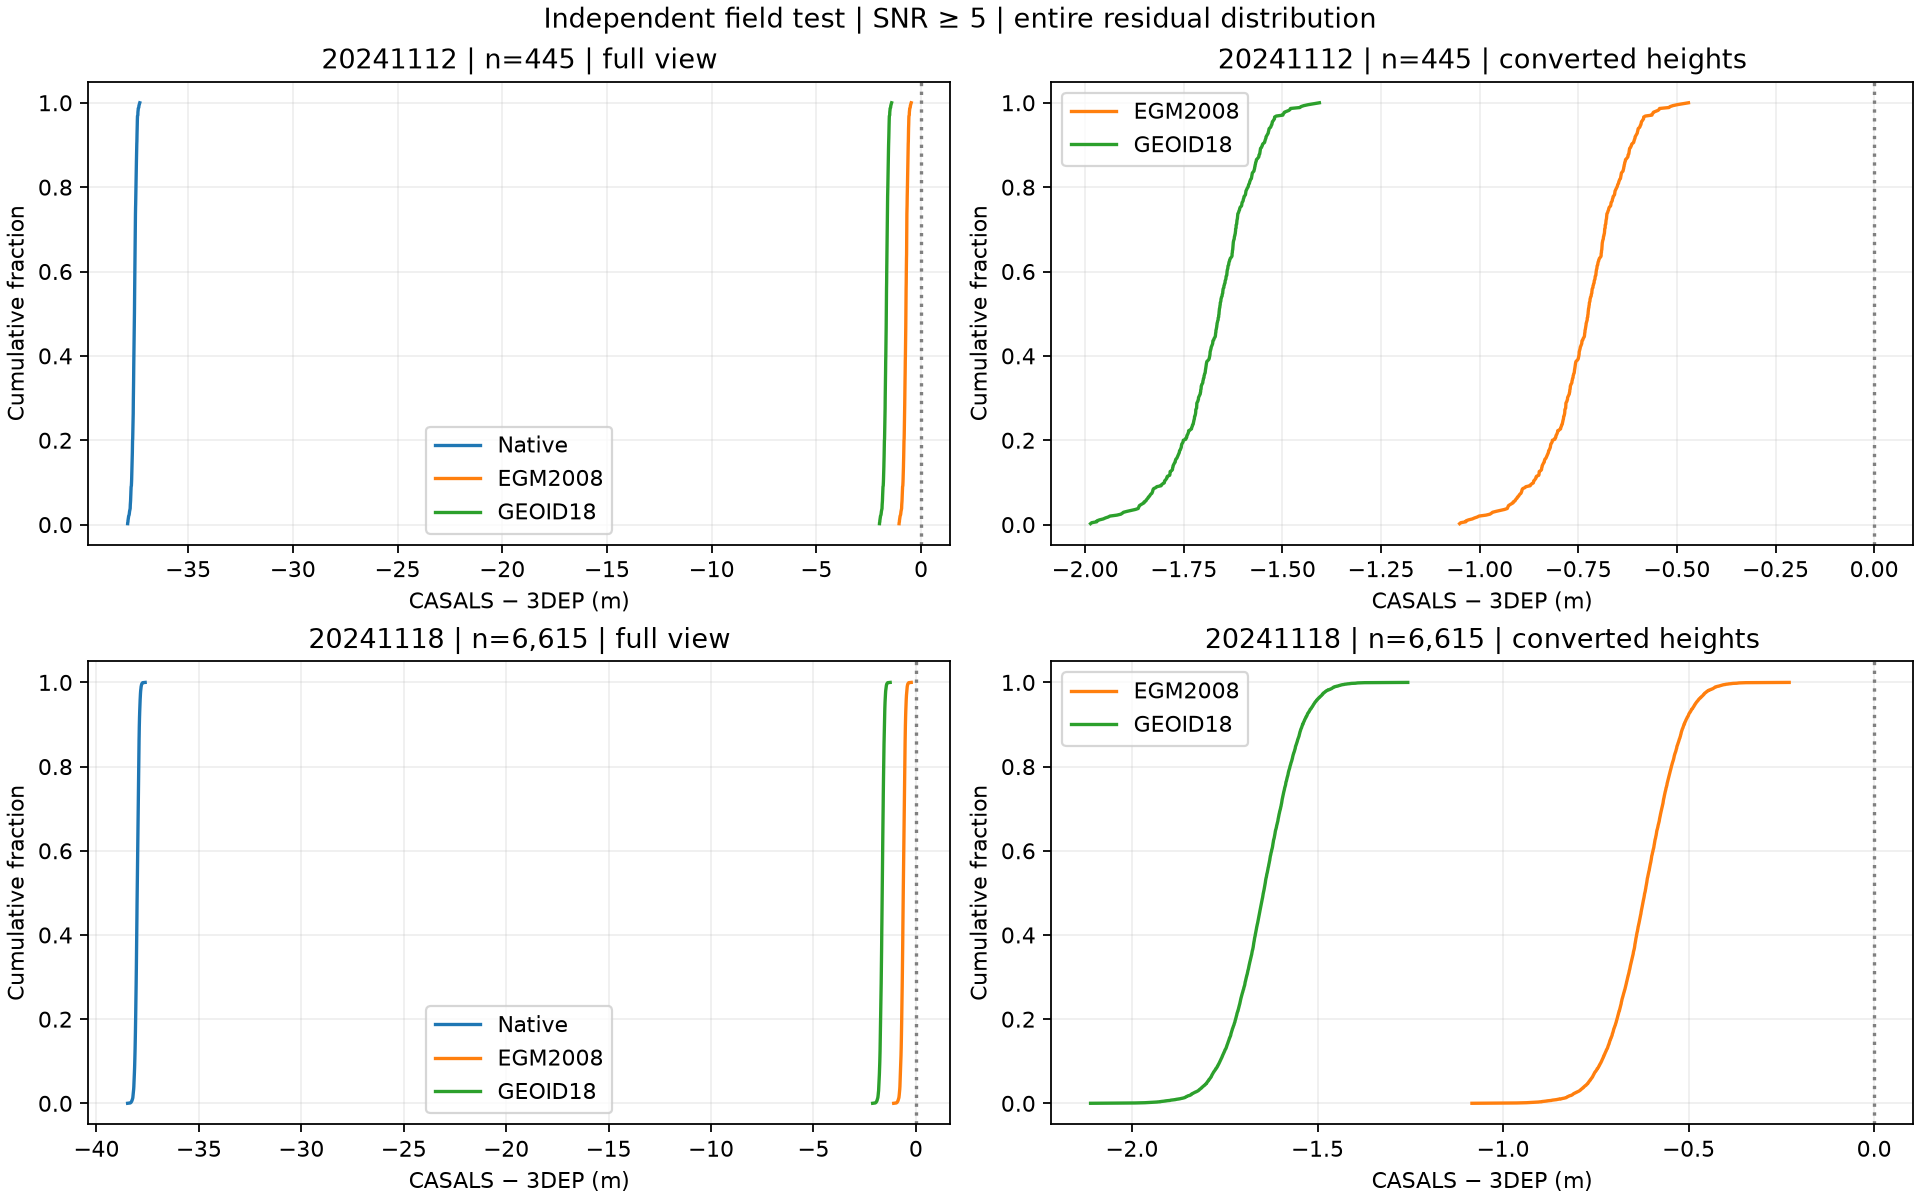

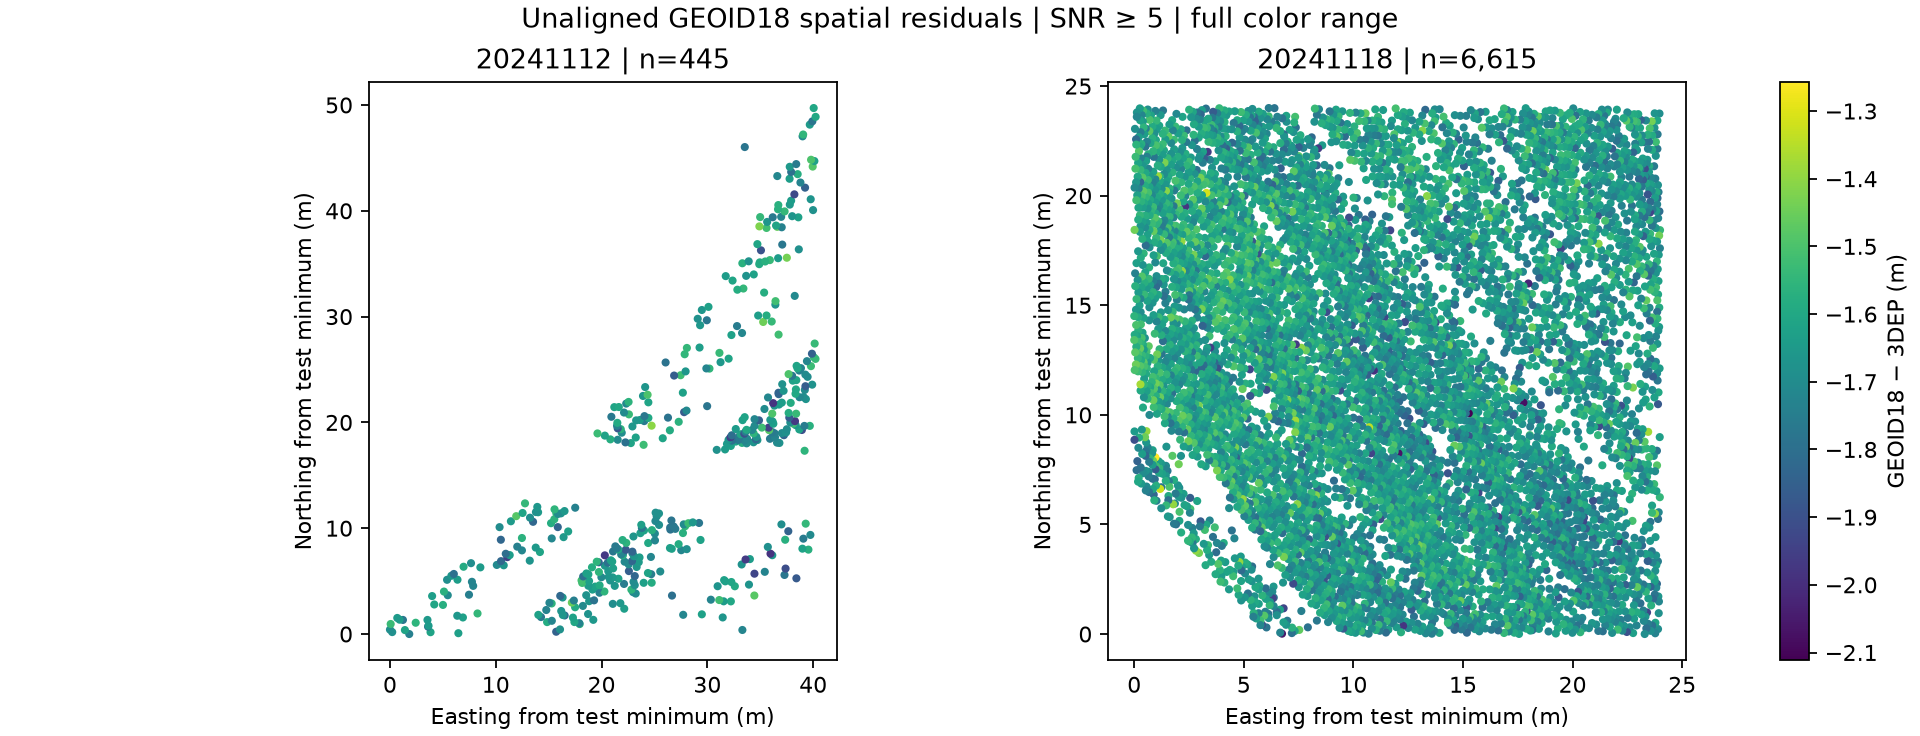

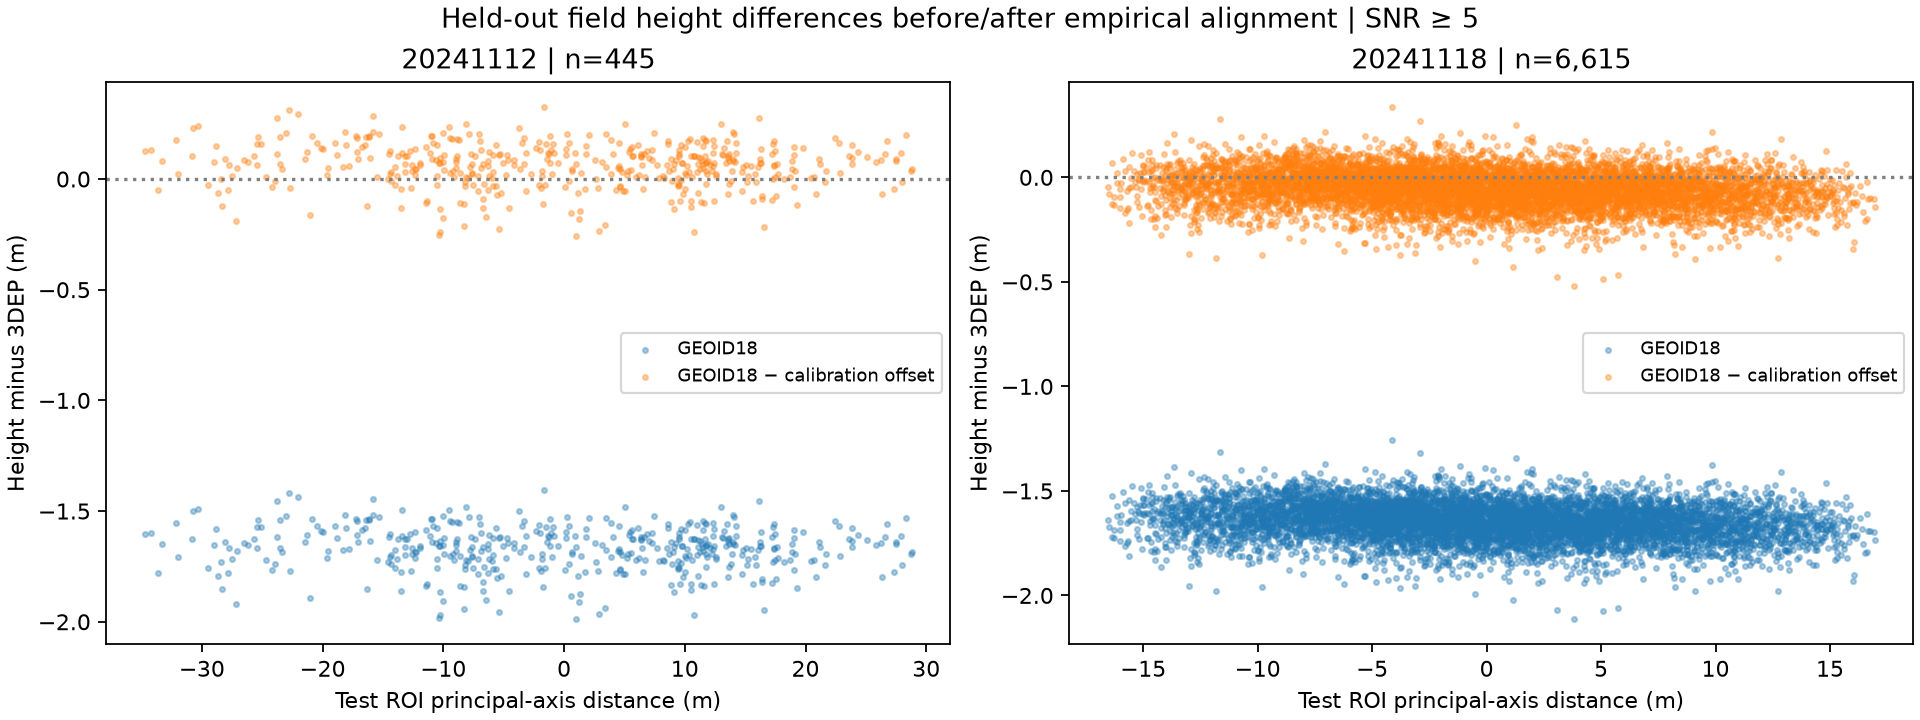

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Image
FIGURES = plot_results(R)
for name, fig in FIGURES:
    display(Image(filename=str(RUN_DIR / name)))
    plt.close(fig)

## Empirical constant-bias transfer

For each method and SNR stratum, `offset = median(transformed height - 3DEP)` on **calibration only**; test `height_aligned = height_transformed - offset`. Calibration and test have disjoint pulse IDs and separated spatial bounding boxes (asserted during execution); their site centers are approximately 760 m / 859 m apart. Offsets are date/site/stratum-specific, not a pooled cross-date fit. The table reports their sources and counts. This examines spatial transfer of a constant bias; it is neither a NAVD88 conversion nor independent absolute accuracy. A constant shifts bias and RMSE while leaving centered dispersion and NMAD unchanged.

In [6]:
ALIGN_COLUMNS = ['granule_id', 'stratum', 'method', 'state', 'offset_m', 'calibration_n', 'test_n',
                 'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(R['alignment'][ALIGN_COLUMNS].round(4))

,granule_id,stratum,method,state,offset_m,calibration_n,test_n,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,before,-37.6465,8987,14885,-13.4546,-37.5635,81.8953,80.7826,0.2954,180.3539
1,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,aligned,-37.6465,8987,14885,24.1919,0.0829,84.3272,80.7826,0.2954,209.1596
2,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,before,-0.8169,8987,14885,23.3833,-0.7257,84.0987,80.7825,0.2957,208.3507
3,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,aligned,-0.8169,8987,14885,24.2002,0.0912,84.3295,80.7825,0.2957,209.1676
4,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,before,-1.7524,8987,14885,22.4477,-1.6613,83.8434,80.7825,0.2957,207.4152
5,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,aligned,-1.7524,8987,14885,24.2002,0.0912,84.3295,80.7825,0.2957,209.1677
6,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,before,-37.6479,2046,4274,-37.3889,-37.5820,38.3468,8.5174,0.1174,37.8136
7,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,aligned,-37.6479,2046,4274,0.2589,0.0659,8.5214,8.5174,0.1174,0.2726
8,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,before,-0.8183,2046,4274,-0.5510,-0.7440,8.5352,8.5174,0.1173,0.9791
9,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,aligned,-0.8183,2046,4274,0.2673,0.0742,8.5216,8.5174,0.1173,0.2762


## Atmospheric context retained from the audit

The full correction audit and ERA5/Ciddor study cannot identify whether the stored neutral delay was already applied. Assuming metres of positive omitted excess slant range gives an upward height sensitivity around 1.59 m / 1.18 m. The independent ERA5 profile supports a metre-scale optical path, but not the stored units, sign, or processing state. No delay compensation is included here. The following **historical road-test** sensitivities use 14 / 70 high-SNR pulses, not the field samples above; their smaller RMSE cannot select a datum or establish an omitted correction.

In [7]:
atmosphere = pd.read_csv(ROOT / 'outputs/notebooks/10_3dep_elevation_validation/final_bias_attribution/physical_hypothesis_metrics.csv')
display(atmosphere.loc[atmosphere.group_type.eq('site') & atmosphere.hypothesis.isin([
    'C7_baseline', 'H1_stored_delay_as_m', 'H1_ERA5_profile_sensitivity']),
    ['granule_id', 'site_id', 'hypothesis', 'n', 'mean_bias_m', 'RMSE_m', 'NMAD_m', 'evidence_status']].round(4))

,granule_id,site_id,hypothesis,n,mean_bias_m,RMSE_m,NMAD_m,evidence_status
0,casals_l1b_20241112T165718_001_02,nov12_county_road_segment_01,C7_baseline,14,-1.8234,1.8262,0.0456,PROVISIONAL_C7_BASELINE
1,casals_l1b_20241112T165718_001_02,nov12_county_road_segment_01,H1_stored_delay_as_m,14,-0.2312,0.2525,0.0456,CONDITIONAL_SENSITIVITY_ONLY
4,casals_l1b_20241112T165718_001_02,nov12_county_road_segment_01,H1_ERA5_profile_sensitivity,14,-0.2174,0.2399,0.0456,CONDITIONAL_SENSITIVITY_ONLY
44,casals_l1b_20241118T171757_001_02,farm_road_segment_01,C7_baseline,70,-1.5713,1.5752,0.1115,PROVISIONAL_C7_BASELINE
45,casals_l1b_20241118T171757_001_02,farm_road_segment_01,H1_stored_delay_as_m,70,-0.3908,0.4061,0.1115,CONDITIONAL_SENSITIVITY_ONLY
48,casals_l1b_20241118T171757_001_02,farm_road_segment_01,H1_ERA5_profile_sensitivity,70,-0.4284,0.4424,0.1115,CONDITIONAL_SENSITIVITY_ONLY


## Final physical interpretation

EGM2008 subtraction removes the large ellipsoid/geoid separation but produces an EGM2008-referenced height, not the documented NAVD88 target. Tide sensitivities shift heights only by centimetres here and do not establish the complete height tide convention. The preferred **target-compatible provisional geodetic path** remains GEOID18/C7, with its unresolved source-frame step explicitly retained.

The final table keeps that unaligned result beside the separate calibration transfer result. Agreement after offset removal indicates how much of the observed mismatch is approximately constant between these sites. It cannot identify whether the remaining bias comes from GNSS frame/epoch, geolocation/ranging conventions, reference mismatch, or seasonal surface returns. Two granules and previously inspected sites do not constitute blind absolute validation.

In [8]:
final = R['alignment'].query("method == 'GEOID18' and stratum == 'snr_ge_5'")[ALIGN_COLUMNS].copy()
final['result_type'] = final.state.map({'before': 'Provisional geodetic transformation', 'aligned': 'Empirical alignment only'})
display(final.round(4))
final.to_csv(RUN_DIR / 'final_summary.csv', index=False)
for gid, rows in final.groupby('granule_id', sort=True):
    before = rows.loc[rows.state.eq('before')].iloc[0]
    after = rows.loc[rows.state.eq('aligned')].iloc[0]
    display(Markdown(f"**{gid[11:19]}:** GEOID18 test n={int(before.test_n):,}, bias {before.mean_bias_m:+.4f} m, RMSE {before.RMSE_m:.4f} m, centered RMSE {before.cRMSE_m:.4f} m. Calibration n={int(before.calibration_n):,}, offset {before.offset_m:+.4f} m; independent-site aligned bias {after.mean_bias_m:+.4f} m and RMSE {after.RMSE_m:.4f} m. NMAD {after.NMAD_m:.4f} m. The systematic mismatch is not eliminated by a verified physical correction."))
    egm = R['metrics'].loc[(R['metrics'].granule_id == gid) & (R['metrics'].population == 'field') & (R['metrics'].stratum == 'snr_ge_5') & (R['metrics'].method == 'EGM2008')].iloc[0]
    display(Markdown(f"EGM2008 bias {egm.mean_bias_m:+.4f} m and RMSE {egm.RMSE_m:.4f} m are numerically smaller, but its vertical reference differs from NAVD88. Centered RMSE is {egm.cRMSE_m:.4f} m versus GEOID18 {before.cRMSE_m:.4f} m: the transformations mainly change bias, with essentially unchanged dispersion."))


,granule_id,stratum,method,state,offset_m,calibration_n,test_n,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m,result_type
16,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,before,-1.7302,94,445,-1.6705,-1.6609,1.6735,0.1005,0.0877,1.8507,Provisional geodetic transformation
17,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,aligned,-1.7302,94,445,0.0597,0.0693,0.1169,0.1005,0.0877,0.2113,Empirical alignment only
34,casals_l1b_20241118T171757_001_02,snr_ge_5,GEOID18,before,-1.5917,3101,6615,-1.6486,-1.6456,1.6510,0.0892,0.0874,1.7972,Provisional geodetic transformation
35,casals_l1b_20241118T171757_001_02,snr_ge_5,GEOID18,aligned,-1.5917,3101,6615,-0.0568,-0.0538,0.1058,0.0892,0.0874,0.2065,Empirical alignment only


**20241112:** GEOID18 test n=445, bias -1.6705 m, RMSE 1.6735 m, centered RMSE 0.1005 m. Calibration n=94, offset -1.7302 m; independent-site aligned bias +0.0597 m and RMSE 0.1169 m. NMAD 0.0877 m. The systematic mismatch is not eliminated by a verified physical correction.

EGM2008 bias -0.7349 m and RMSE 0.7417 m are numerically smaller, but its vertical reference differs from NAVD88. Centered RMSE is 0.1005 m versus GEOID18 0.1005 m: the transformations mainly change bias, with essentially unchanged dispersion.

**20241118:** GEOID18 test n=6,615, bias -1.6486 m, RMSE 1.6510 m, centered RMSE 0.0892 m. Calibration n=3,101, offset -1.5917 m; independent-site aligned bias -0.0568 m and RMSE 0.1058 m. NMAD 0.0874 m. The systematic mismatch is not eliminated by a verified physical correction.

EGM2008 bias -0.6208 m and RMSE 0.6272 m are numerically smaller, but its vertical reference differs from NAVD88. Centered RMSE is 0.0892 m versus GEOID18 0.0892 m: the transformations mainly change bias, with essentially unchanged dispersion.